# Cameron Peak and East Troublesome Fire Burn Severity
## Burn Severity by Watershed

- **Objective:**
For this notebook, the Key and Benson burn severity map from 02_burn_severity is summarized by HUC12 subwatershed, to show where the 2020 Cameron Peak and East Troublesome fires burned most severely.

- **Objective goals:**
    - Total the area in each burn severity class for every subwatershed the fires burned
    - Rank the subwatersheds by the percent of their area burned at high severity
    - Map the results and save the table

---

### Methodology

#### 1. Burn Severity in Each Subwatershed
- Total the area in each burn severity class inside the perimeters, for each subwatershed

#### 2. Map and Rank the Subwatersheds
- Map the percent of each subwatershed burned at high severity
- Rank the subwatersheds with the most high severity

#### 3. Save the Results
- Save the subwatershed table and the interactive map

#### 4. Summary
- Sum up where the fires burned most severely

# Libraries

In [1]:
### file paths, OS operations, utilities
import os
import pathlib

### data handling
import numpy as np
import pandas as pd
import geopandas as gpd

### rasters
import rioxarray as rxr
from rasterio.features import geometry_mask

### visualization
import hvplot.pandas
import matplotlib.pyplot as plt

# Primary Directory

In [2]:
### set up root file path
# Walk up from the current directory to find the repo root (contains .git)
_cwd = pathlib.Path(os.getcwd()).resolve()
repo_root = next(
    (p for p in [_cwd] + list(_cwd.parents) if (p / '.git').exists()),
    _cwd
)
os.chdir(repo_root)

data_dir = os.path.join(repo_root, 'data')
os.makedirs(data_dir, exist_ok=True)

print('Repo root:', repo_root)

Repo root: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity


# Secondary Directories

In [3]:
### set a directory for the burn severity by watershed results
watershed_severity_dir = os.path.join(data_dir, 'watershed_severity')
os.makedirs(watershed_severity_dir, exist_ok=True)

# Load the Saved Data
These are the Universal Calls cells from 01_data_download and 02_burn_severity, which load the data saved there.

In [4]:
### root dir
data_dir = os.path.join(repo_root, 'data')

### fire names used in the file names
fire_keys = ["cameron_peak", "east_troublesome"]


### PERIMETERS AND STUDY AREAS
perimeters_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'nifc_perimeters.gpkg'))
study_area_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'study_areas.gpkg'))


### MTBS
### fire records and dNBR thresholds
mtbs_fires_df = pd.read_csv(os.path.join(data_dir, 'mtbs', 'mtbs_fires.csv'))

### MTBS boundaries
mtbs_gdf = gpd.read_file(os.path.join(data_dir, 'mtbs', 'mtbs_boundaries.gpkg'))

### MTBS burn severity maps
mtbs_paths = {}
for fire in fire_keys:
    mtbs_paths[fire] = os.path.join(data_dir, 'mtbs', 'mtbs_' + fire + '_2020.tif')


### WATERSHEDS
huc12_gdf = gpd.read_file(os.path.join(data_dir, 'watersheds', 'huc12.gpkg'))


### WUI
wui_path = os.path.join(data_dir, 'wui', 'wui_CO_2019_clip.tif')


### HLS COMPOSITES
### e.g. hls_paths[("cameron_peak", 2021)]["nbr"]
hls_paths = {}
for fire in fire_keys:
    for year in range(2019, 2027):
        fire_hls_dir = os.path.join(data_dir, 'hls', fire)
        file_start = "hls_" + fire + "_" + str(year)
        hls_paths[(fire, year)] = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }

In [5]:
### BURN SEVERITY
severity_dir = os.path.join(data_dir, 'severity')

### Key and Benson class numbers, names, thresholds, and colors
severity_classes_df = pd.read_csv(os.path.join(severity_dir, 'severity_classes.csv'))

### acres and percent of each fire in each class
severity_area_df = pd.read_csv(os.path.join(severity_dir, 'severity_area.csv'))

### dNBR and burn severity classes for each fire, e.g. dnbr_paths["cameron_peak"]
dnbr_paths = {}
severity_class_paths = {}
for fire in fire_keys:
    dnbr_paths[fire] = os.path.join(severity_dir, fire, fire + '_dnbr.tif')
    severity_class_paths[fire] = os.path.join(severity_dir, fire, fire + '_severity_classes.tif')

### Settings

In [6]:
### projected coordinate system of the rasters: UTM zone 13N (meters)
utm_crs = "EPSG:32613"

### pixel size of the burn severity rasters (meters)
cell_size = 30

### square meters in one acre, and acres in one square kilometer
m2_per_acre = 4046.8564224
acres_per_km2 = 247.105381

# 1. Burn Severity in Each Subwatershed
For each fire, every subwatershed that overlaps or is within the fire perimeter is checked. For the part of each subwatershed inside the perimeter, the area in each Key and Benson class is added up. A subwatershed that both fires burned gets the area from both added together.

In [7]:
### project the perimeters and subwatersheds to UTM zone 13N to match the rasters
perimeters_utm = perimeters_gdf.to_crs(utm_crs)
huc12_utm = huc12_gdf.to_crs(utm_crs)

### Key and Benson class names, in class number order
class_names = list(severity_classes_df.sort_values("number")["class"])

### acres of each class inside each fire perimeter, for every subwatershed that overlaps or is within the fire
rows = []

for fire in fire_keys:

    ### open the burn severity classes (0 is no data)
    classes_da = rxr.open_rasterio(severity_class_paths[fire]).squeeze()
    classes = classes_da.values
    transform = classes_da.rio.transform()

    ### pixels inside the fire perimeter
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    inside = geometry_mask(perimeter.geometry, out_shape=classes.shape, transform=transform, invert=True)

    ### the subwatersheds that overlap or are within the perimeter
    fire_huc12 = huc12_utm[huc12_utm.intersects(perimeter.union_all())]

    for i, watershed in fire_huc12.iterrows():

        ### pixels inside the subwatershed
        in_watershed = geometry_mask([watershed.geometry], out_shape=classes.shape, transform=transform, invert=True)

        ### pixels inside both the subwatershed and the perimeter
        values = classes[inside & in_watershed]

        ### acres of each class
        row = {"huc12": watershed["huc12"], "fire": fire}
        for number, name in enumerate(class_names, start=1):
            row[name] = (values == number).sum() * cell_size**2 / m2_per_acre
        rows.append(row)

fire_huc12_df = pd.DataFrame(rows)

In [8]:
### add up the two fires for subwatersheds that both fires burned
severity_df = fire_huc12_df.groupby("huc12")[class_names].sum()
severity_df["fire"] = fire_huc12_df.groupby("huc12")["fire"].agg(", ".join)
severity_df = severity_df.reset_index()

### burned area (inside the perimeters) and high severity area
severity_df["burned_acres"] = severity_df[class_names].sum(axis=1)
severity_df["high_acres"] = severity_df["High"]

### keep the subwatersheds with burned area (some only touch a perimeter at the edge)
severity_df = severity_df[severity_df["burned_acres"] > 0]

### add the subwatershed names, areas, and outlines
watershed_severity_gdf = huc12_utm[["huc12", "name", "areasqkm", "geometry"]].merge(severity_df, on="huc12")
watershed_severity_gdf["watershed_acres"] = watershed_severity_gdf["areasqkm"] * acres_per_km2

### percent of each subwatershed that burned, and that burned at high severity
watershed_severity_gdf["percent_burned"] = watershed_severity_gdf["burned_acres"] / watershed_severity_gdf["watershed_acres"] * 100
watershed_severity_gdf["percent_high"] = watershed_severity_gdf["high_acres"] / watershed_severity_gdf["watershed_acres"] * 100

### sort from the most high severity to the least
watershed_severity_gdf = watershed_severity_gdf.sort_values("percent_high", ascending=False).reset_index(drop=True)

### check it
print(len(watershed_severity_gdf), "subwatersheds burned")
watershed_severity_gdf[["name", "fire", "watershed_acres", "burned_acres", "high_acres", "percent_burned", "percent_high"]].head(10).round(1)

50 subwatersheds burned


,name,fire,watershed_acres,burned_acres,high_acres,percent_burned,percent_high
0,Little Beaver Creek,cameron_peak,11571.9,11563.9,4655.2,99.9,40.2
1,Miller Fork,cameron_peak,8940.3,8535.1,3271.4,95.5,36.6
2,Sheep Creek,cameron_peak,13976.3,13331.7,4574.2,95.4,32.7
3,Headwaters Willow Creek,east_troublesome,14282.7,8619.4,4503.5,60.3,31.5
4,Upper Buckhorn Creek,cameron_peak,27391.6,20245.3,7765.6,73.9,28.4
5,Onahu Creek-Colorado River,east_troublesome,24384.4,17661.7,6504.8,72.4,26.7
6,Hague Creek,cameron_peak,8690.7,4043.4,1927.5,46.5,22.2
7,Black Hollow-Cache la Poudre River,cameron_peak,37765.1,33955.0,7480.3,89.9,19.8
8,Middle Buckhorn Creek,cameron_peak,25377.7,17915.9,4535.3,70.6,17.9
9,Bennett Creek,cameron_peak,9217.0,7575.7,1508.5,82.2,16.4


# 2. Map and Rank the Subwatersheds

In [9]:
### round the values shown when hovering over the map
map_gdf = watershed_severity_gdf.to_crs(epsg=4326)
map_gdf["percent_high"] = map_gdf["percent_high"].round(1)
map_gdf["high_acres"] = map_gdf["high_acres"].round(0)

### plot the percent of each subwatershed burned at high severity
watershed_plot = map_gdf.hvplot(
    geo=True,
    tiles="EsriImagery",
    c="percent_high",
    cmap="Blues",
    clabel="% of subwatershed at high severity",
    line_color="white",
    line_width=1,
    alpha=0.85,
    hover_cols=["name", "huc12", "high_acres", "percent_high"],
    title="Percent of Each Subwatershed Burned at High Severity",
    frame_width=700
)

### add the fire perimeters
fires_plot = perimeters_gdf.hvplot(
    geo=True,
    fill_color=None,
    line_color="#000000",
    line_width=2
)

### put the perimeters on top of the subwatersheds
watershed_map = watershed_plot * fires_plot
watershed_map

:Overlay
   .WMTS.I      :WMTS   [Longitude,Latitude]
   .Polygons.I  :Polygons   [Longitude,Latitude]   (percent_high,name,huc12,high_acres)
   .Polygons.II :Polygons   [Longitude,Latitude]

Figure 1: Percent of each burned subwatershed's area that burned at high severity, with the fire perimeters in black. Hover over a subwatershed to see its name.

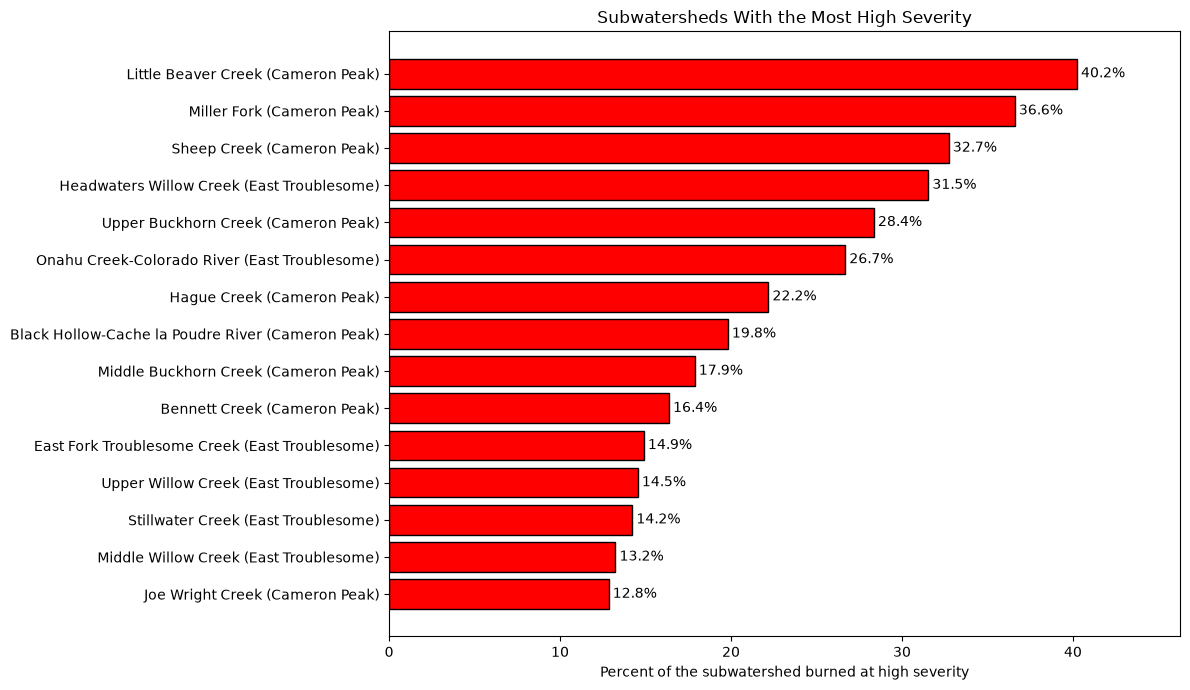

In [10]:
### the 15 subwatersheds with the highest percent of their area at high severity
top_df = watershed_severity_gdf.head(15)
fire_names = {"cameron_peak": "Cameron Peak", "east_troublesome": "East Troublesome", "cameron_peak, east_troublesome": "Both fires"}
labels = [name + " (" + fire_names[fire] + ")" for name, fire in zip(top_df["name"], top_df["fire"])]

### plot them as bars, with the percent at the end of each bar
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(labels, top_df["percent_high"], color="#ff0000", edgecolor="black")
ax.bar_label(bars, labels=[str(round(value, 1)) + "%" for value in top_df["percent_high"]], padding=3)

### highest on top
ax.invert_yaxis()
ax.set_xlabel("Percent of the subwatershed burned at high severity")
ax.set_title("Subwatersheds With the Most High Severity")
ax.set_xlim(0, top_df["percent_high"].max() * 1.15)

plt.tight_layout()
plt.show()

Figure 2: The 15 subwatersheds with the highest percent of their total area burned at high severity, and the fire that burned them.

# 3. Save the Results
The subwatershed table is saved as a GeoPackage with the outlines, and as a CSV without them. The interactive map (Figure 1) is saved as a web page, which the blog shows.

In [11]:
### columns to save
save_columns = ["huc12", "name", "fire", "watershed_acres", "burned_acres", "high_acres", "percent_burned", "percent_high"] + class_names

### save the table with the outlines, and without them
gpkg_path = os.path.join(watershed_severity_dir, "huc12_severity.gpkg")
watershed_severity_gdf[save_columns + ["geometry"]].to_file(gpkg_path, driver="GPKG")

csv_path = os.path.join(watershed_severity_dir, "huc12_severity.csv")
watershed_severity_gdf[save_columns].to_csv(csv_path, index=False)

### save the interactive map as a web page, for the blog
map_path = os.path.join(watershed_severity_dir, "huc12_severity_map.html")
hvplot.save(watershed_map, map_path)

print("Saved subwatershed table to:", gpkg_path)
print("Saved subwatershed table to:", csv_path)
print("Saved interactive map to:", map_path)

Saved subwatershed table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\watershed_severity\huc12_severity.gpkg
Saved subwatershed table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\watershed_severity\huc12_severity.csv
Saved interactive map to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\watershed_severity\huc12_severity_map.html


# 4. Summary
Seven subwatersheds had 20% or more of their total area burn at high severity, five at Cameron Peak and two at East Troublesome:
- **Cameron Peak:** the most high severity was in the Cache la Poudre River basin (Little Beaver Creek at 40%, Sheep Creek at 33%, and Hague Creek at 22%) and the Big Thompson River basin (Miller Fork at 37% and Upper Buckhorn Creek at 28%)
- **East Troublesome:** the most high severity was in the Colorado River headwaters, in the Headwaters Willow Creek (32%) and Onahu Creek-Colorado River (27%) subwatersheds
- No subwatershed was burned by both fires

The Key and Benson map has less high severity than MTBS (03_mtbs_comparison), so these percents are on the low side.

# Citations
- Key, C. H., & Benson, N. C. (2006). Landscape assessment (LA): Sampling and analysis methods. In D. C. Lutes et al. (Eds.), *FIREMON: Fire effects monitoring and inventory system* (Gen. Tech. Rep. RMRS-GTR-164-CD, pp. LA-1-LA-55). USDA Forest Service, Rocky Mountain Research Station.